# Your first UN table in 5 minutes

This notebook gets official UN statistics into a table, a chart, a sentence for your report and an Excel file, with the source on every row. You don't need to know Python: run each cell in order with **Shift + Enter** (or the ▶ button), and change the words in quotes to ask your own question.

It uses [undata](https://nerd-factory.github.io/undata/), a free, open-source package for the [UN System Data Commons](https://data.un.org), which holds statistics from 26 UN System entities. undata is a personal open-source project, not an official UN product, and the data belongs to the agencies that publish it.

## 1. Install undata
This takes about 20 seconds the first time.

In [ ]:
%pip install -q "undata[charts]"

In [2]:
%matplotlib inline
import undata as un

## 2. Find the indicator you need
Describe what you want to measure in plain words. Each row is one indicator: who publishes it, how many places have data, and for which years. Copy the id from the first column.

In [3]:
un.search("maternal mortality")

,indicator,name,source,places,years,breakdowns
0,undata/unicef/MNCH_MMR.SEX--F,Maternal mortality ratio (number of maternal d...,UNICEF,201,2000-2023,0
1,undata/who/GHE_YLL,Years of life lost from mortality,WHO,9,2012-2012,2
2,undata/sdg/SH_STA_MORT.SEX--F,Maternal mortality ratio [Sex=Female],Global SDG Indicators Database,233,2000-2023,0
3,undata/who/GHE_YLL_RATE,Rate of yars of life lost from mortality,WHO,10,2000-2012,1
4,undata/undphdro/GII_mmr.SEX--F,Maternal mortality ratio [Sex=Female],UNDP HDRO,184,1990-2023,0
5,undata/unicef/MNCH_MATERNAL_DEATHS.SEX--F,Estimated number maternal deaths [Sex=Female],UNICEF,201,2000-2023,0
6,undata/who/MORT_PROJ_RATE,Projected death rate,WHO,10,2015-2030,9
7,undata/who/MORT_PROJ_CNT,Projected number of deaths,WHO,10,2015-2030,11


## 3. Get the numbers
Paste an indicator id, or use an SDG number such as `3.1.1`. Write countries the way you would in an email, separated by commas. You can also use regions or groups, such as `Southern Asia` or `LDCs`.

In Google Colab, these two fields appear as boxes you can type into.

In [4]:
indicator = "3.1.1"  # @param {type:"string"}
places = "Bangladesh, Viet Nam"  # @param {type:"string"}

table = un.get(indicator, [p.strip() for p in places.split(",")])
table.tail()

,country,iso3,year,value,unit,indicator_name,indicator,source,source_url
43,Viet Nam,VNM,2019,52.20333,"Count per 100,000 live births",Maternal mortality ratio [Sex=Female],undata/sdg/SH_STA_MORT.SEX--F,SDG Global Database,https://unstats.un.org/sdgs/dataportal
44,Viet Nam,VNM,2020,51.33381,"Count per 100,000 live births",Maternal mortality ratio [Sex=Female],undata/sdg/SH_STA_MORT.SEX--F,SDG Global Database,https://unstats.un.org/sdgs/dataportal
45,Viet Nam,VNM,2021,52.23593,"Count per 100,000 live births",Maternal mortality ratio [Sex=Female],undata/sdg/SH_STA_MORT.SEX--F,SDG Global Database,https://unstats.un.org/sdgs/dataportal
46,Viet Nam,VNM,2022,49.10460,"Count per 100,000 live births",Maternal mortality ratio [Sex=Female],undata/sdg/SH_STA_MORT.SEX--F,SDG Global Database,https://unstats.un.org/sdgs/dataportal
47,Viet Nam,VNM,2023,47.61028,"Count per 100,000 live births",Maternal mortality ratio [Sex=Female],undata/sdg/SH_STA_MORT.SEX--F,SDG Global Database,https://unstats.un.org/sdgs/dataportal


Every row carries the **unit**, the **year** and the **source**, so a number can never lose track of where it came from.

## 4. Chart it
undata picks a chart that fits the table, and puts the source underneath.

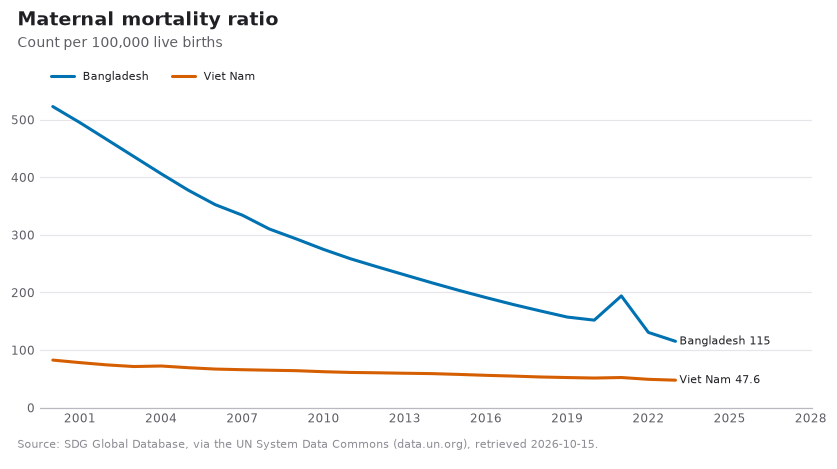

In [5]:
un.chart(table)

## 5. The sentence for your report
Worked out from the numbers, not typed in.

In [6]:
print(un.describe(table))

Maternal mortality ratio [Sex=Female] (count per 100,000 live births):
  Bangladesh fell from 523 in 2000 to 115 in 2023 (-78%).
  Viet Nam fell from 82.5 in 2000 to 47.6 in 2023 (-42%).


## 6. Save it to Excel, with the citations
The data goes on one sheet, the sources on the next, and how complete the table is on a third. In Colab, the file downloads to your computer.

In [7]:
un.save(table, "my-un-table.xlsx")

try:
    from google.colab import files  # only exists in Colab

    files.download("my-un-table.xlsx")
except ImportError:
    print("Saved my-un-table.xlsx next to this notebook.")

Saved my-un-table.xlsx next to this notebook.


## 7. Cite the agency, not the website

In [8]:
print(un.cite(table))

SDG Global Database. Maternal mortality ratio [Sex=Female] (undata/sdg/SH_STA_MORT.SEX--F). https://unstats.un.org/sdgs/dataportal. Retrieved 2026-10-15 from the UN System Data Commons, https://data.un.org.


## One more: is it on track for 2030?
The UN Statistics Division's own progress method, for all 44 least developed countries, in one call. `better="lower"` says that a fall is progress, and `target=70` is SDG Target 3.1.

In [9]:
progress = un.progress("3.1.1", "LDCs", better="lower", target=70)
progress[["country", "status", "baseline_value", "latest_value", "projected"]].head(10)

,country,status,baseline_value,latest_value,projected
0,Mozambique,On track or target met,182.45146,82.21794,40.931573
1,Zambia,On track or target met,154.40590,85.45037,50.919338
2,Bangladesh,On track or target met,203.53675,115.11493,69.913230
3,Lao People's Democratic Republic,On track or target met,179.64726,112.15137,74.261817
4,Kiribati,"Moderate progress, but acceleration needed",90.38566,79.76224,71.496194
5,Ethiopia,"Moderate progress, but acceleration needed",400.69462,194.93685,103.774183
6,Nepal,"Moderate progress, but acceleration needed",235.64067,142.00527,91.169988
7,Uganda,"Moderate progress, but acceleration needed",299.16160,170.31048,104.030326
8,Sierra Leone,"Moderate progress, but acceleration needed",730.10593,353.56356,187.462290
9,South Sudan,"Moderate progress, but acceleration needed",1435.57864,691.82029,365.248814


In [10]:
print(un.describe(progress))

Maternal mortality ratio, 44 countries. Each country's trend since 2015 (or the first year after) is projected to 2030 and compared with the target of 70.0. 4 on track or target met (Bangladesh, Lao People's Democratic Republic, Mozambique, Zambia); 24 moderate progress, but acceleration needed; 15 marginal progress, and significant acceleration needed; 1 regression (Tuvalu). Method: UN Statistics Division, The Sustainable Development Goals Report 2026: Technical Note for Progress Assessment.


## Where next

- **Twelve worked examples**, from a country briefing to the rural-urban gap: https://nerd-factory.github.io/undata/
- **Six two-minute videos**: https://www.youtube.com/playlist?list=PLCLeVAwBLQNs
- **Every function explained**: https://nerd-factory.github.io/undata/reference/
- **Something didn't work, or you need an indicator we don't cover?** Open an issue: https://github.com/nerd-factory/undata/issues

Created and maintained by Mafizul Islam · MIT licence